# ĐỒ ÁN 1 (GIỮA KỲ): NHẬN DẠNG CHỮ SỐ VIẾT TAY (MNIST)
## 1. TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU MNIST

---
### CẤU TRÚC VÀ QUY TRÌNH THỰC HIỆN:
1. **Tải và nạp dữ liệu MNIST gốc:** Tải trực tiếp định dạng nhị phân chuẩn gồm 70.000 mẫu ảnh $28 \times 28$.
2. **Kiểm tra chất lượng dữ liệu (Data Integrity Check):** Đảm bảo không có giá trị khuyết thiếu (NaN/Inf), dải điểm ảnh đúng $[0, 255]$ và nhãn hợp lệ $[0..9]$.
3. **Phân chia tập dữ liệu:** Chia 60.000 ảnh huấn luyện gốc thành 50.000 ảnh Train và 10.000 ảnh Validation; giữ nguyên 10.000 ảnh Test độc lập (chặn Data Leakage).
4. **Tiền xử lý dữ liệu:** Chuẩn hóa z-score toàn cục, chuẩn hóa z-score theo từng đặc trưng (Standardizer) và chuẩn hóa Min-Max $[0, 1]$; làm phẳng vector 784 chiều.
5. **Khám phá và trực quan hóa dữ liệu (EDA):**
   - Phân bố 10 lớp trên cả 3 tập (Train, Validation, Test).
   - Phân tích cường độ điểm ảnh, dead pixels ở viền ảnh và bản đồ độ lệch chuẩn.
   - Trực quan hóa ảnh trung bình 10 chữ số và định lượng lượng mực tiêu thụ.
   - Ma trận khoảng cách Euclid $10 \times 10$ và xác định các cặp số dễ nhầm lẫn nhất.
6. **Lưu trữ dữ liệu tiền xử lý:** Xuất tệp nén `mnist_preprocessed.npz` và `split_indices.npz` để tái sử dụng xuyên suốt toàn bộ đồ án.

In [40]:
# 0. THIẾT LẬP MÔI TRƯỜNG, THƯ VIỆN VÀ SEED
import os
import gzip
import shutil
import time
import copy
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from sklearn.model_selection import train_test_split

# Cố định Seed ngẫu nhiên để đảm bảo tính tái lập (Replicability)
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Tắt autograd để đảm bảo tính toán from-scratch
torch.set_grad_enabled(False)

# Cấu hình Matplotlib chuyên nghiệp phục vụ báo cáo
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Tạo cấu trúc thư mục lưu trữ kết quả và dữ liệu
DATA_ROOT = "./data"
ARTIFACTS_DIR = "./artifacts"
PROCESSED_DIR = "./data/processed"
FIGURES_DIR = "./figures"

for d in [DATA_ROOT, ARTIFACTS_DIR, PROCESSED_DIR, FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)

print("Thiết lập môi trường thành công!")
print(f" PyTorch Version: {torch.__version__} | Số luồng CPU: {torch.get_num_threads()}")
print(f" Random Seed: {SEED} (đã khóa cho torch và numpy)")


Thiết lập môi trường thành công!
 PyTorch Version: 2.14.1 | Số luồng CPU: 4
 Random Seed: 42 (đã khóa cho torch và numpy)


---
## 1. TẢI VÀ NẠP DỮ LIỆU MNIST GỐC

Bộ dữ liệu chuẩn **MNIST (Modified National Institute of Standards and Technology)** gồm 70.000 ảnh xám kích thước $28 \times 28$ điểm ảnh của các chữ số viết tay từ 0 đến 9 (60.000 ảnh huấn luyện gốc và 10.000 ảnh kiểm thử chuẩn).

Cơ chế tải và đọc dữ liệu:
- Nạp thông qua `torchvision.datasets.MNIST(..., download=True)`.
- Nếu máy chủ mặc định của torchvision gặp sự cố mạng, hàm tự động chuyển sang mirror GitHub dự phòng (`_download_from_mirror`) giải nén đúng 4 tệp nhị phân IDX tiêu chuẩn vào `./data/MNIST/raw`.

In [41]:
# 1.1. CÁC HÀM TẢI VÀ NẠP DỮ LIỆU MNIST
DATA_ROOT = "./data"
MNIST_FILES = ["train-images-idx3-ubyte", "train-labels-idx1-ubyte",
               "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]
GITHUB_MIRROR = "https://raw.githubusercontent.com/fgnt/mnist/master/"


def _download_from_mirror(root):
    raw = os.path.join(root, "MNIST", "raw")
    os.makedirs(raw, exist_ok=True)
    for name in MNIST_FILES:
        dst = os.path.join(raw, name)
        if os.path.exists(dst):
            continue
        gz = dst + ".gz"
        urllib.request.urlretrieve(GITHUB_MIRROR + name + ".gz", gz)
        with gzip.open(gz, "rb") as f_in, open(dst, "wb") as f_out:
            shutil.copyfileobj(f_in, f_out)


def load_mnist(root=DATA_ROOT):
    try:
        train = torchvision.datasets.MNIST(root, train=True, download=True)
        test = torchvision.datasets.MNIST(root, train=False, download=True)
    except Exception as e:
        print("Nguon mac dinh cua torchvision loi (", type(e).__name__, "), chuyen sang mirror GitHub")
        _download_from_mirror(root)
        train = torchvision.datasets.MNIST(root, train=True, download=False)
        test = torchvision.datasets.MNIST(root, train=False, download=False)
    return train.data, train.targets, test.data, test.targets


# Nạp dữ liệu thô
Xtr_raw, ytr_raw, Xte_raw, yte_raw = load_mnist(DATA_ROOT)

print(f"Tải và nạp dữ liệu MNIST thành công:")
print(f" Xtr_raw (train gốc): {tuple(Xtr_raw.shape)}, dtype = {Xtr_raw.dtype}")
print(f" ytr_raw (nhãn train): {tuple(ytr_raw.shape)}, dtype = {ytr_raw.dtype}")
print(f" Xte_raw (test gốc) : {tuple(Xte_raw.shape)}, dtype = {Xte_raw.dtype}")
print(f" yte_raw (nhãn test) : {tuple(yte_raw.shape)}, dtype = {yte_raw.dtype}")


Tải và nạp dữ liệu MNIST thành công:
 Xtr_raw (train gốc): (60000, 28, 28), dtype = torch.uint8
 ytr_raw (nhãn train): (60000,), dtype = torch.int64
 Xte_raw (test gốc) : (10000, 28, 28), dtype = torch.uint8
 yte_raw (nhãn test) : (10000,), dtype = torch.int64


---
## 2. KIỂM TRA CHẤT LƯỢNG VÀ TOÀN VẸN DỮ LIỆU (DATA INTEGRITY CHECK)

Trước khi phân chia tập và đưa vào mô hình học máy, quy trình kiểm tra chất lượng dữ liệu bao gồm:
1. Giá trị khuyết thiếu (`NaN`) hoặc giá trị vô cùng (`Inf`).
2. Dải giá trị điểm ảnh có nằm chính xác trong đoạn $[0, 255]$ của ảnh xám 8-bit hay không.
3. Nhãn lớp có đủ 10 chữ số từ 0 đến 9 và không chứa nhãn bất thường.
4. Kiểm tra sự trùng lặp và tính toàn vẹn của dữ liệu gốc.

In [42]:
# 2.1. KIỂM TRA TOÀN DIỆN CHẤT LƯỢNG DỮ LIỆU GỐC
Xtr_np = Xtr_raw.numpy()
ytr_np = ytr_raw.numpy()
Xte_np = Xte_raw.numpy()
yte_np = yte_raw.numpy()

# 1. Kiểm tra NaN và Inf
nan_tr = np.isnan(Xtr_np).sum()
nan_te = np.isnan(Xte_np).sum()
inf_tr = np.isinf(Xtr_np).sum()
inf_te = np.isinf(Xte_np).sum()

# 2. Kiểm tra dải điểm ảnh [0, 255]
min_tr, max_tr = Xtr_np.min(), Xtr_np.max()
min_te, max_te = Xte_np.min(), Xte_np.max()

# 3. Kiểm tra nhãn
classes_tr = np.unique(ytr_np)
classes_te = np.unique(yte_np)

# 4. Kiểm tra pixel hằng số (Dead pixels = 0 trên toàn bộ tập train)
dead_pixels_count = (Xtr_np.reshape(len(Xtr_np), -1) == 0).all(axis=0).sum()

check_df = pd.DataFrame([
    {"Hạng mục kiểm tra": "Kích thước tập ảnh (N x H x W)", "Tập Train gốc": f"{Xtr_np.shape}", "Tập Test gốc": f"{Xte_np.shape}", "Trạng thái": "✓ Chuẩn 28x28"},
    {"Hạng mục kiểm tra": "Giá trị thiếu (NaN) / Vô cùng (Inf)", "Tập Train gốc": f"{nan_tr} / {inf_tr}", "Tập Test gốc": f"{nan_te} / {inf_te}", "Trạng thái": "✓ Không có lỗi"},
    {"Hạng mục kiểm tra": "Dải giá trị điểm ảnh", "Tập Train gốc": f"[{min_tr}, {max_tr}]", "Tập Test gốc": f"[{min_te}, {max_te}]", "Trạng thái": "✓ Đủ dải 8-bit [0, 255]"},
    {"Hạng mục kiểm tra": "Các lớp nhãn xuất hiện", "Tập Train gốc": f"{classes_tr.tolist()}", "Tập Test gốc": f"{classes_te.tolist()}", "Trạng thái": "✓ Đủ 10 chữ số (0..9)"},
    {"Hạng mục kiểm tra": "Số điểm ảnh luôn bằng 0 (Dead pixels)", "Tập Train gốc": f"{dead_pixels_count} / 784 pixels", "Tập Test gốc": "-", "Trạng thái": "i Thuộc viền biên ngoài"}
])

display(check_df)


,Hạng mục kiểm tra,Tập Train gốc,Tập Test gốc,Trạng thái
0,Kích thước tập ảnh (N x H x W),"(60000, 28, 28)","(10000, 28, 28)",✓ Chuẩn 28x28
1,Giá trị thiếu (NaN) / Vô cùng (Inf),0 / 0,0 / 0,✓ Không có lỗi
2,Dải giá trị điểm ảnh,"[0, 255]","[0, 255]","✓ Đủ dải 8-bit [0, 255]"
3,Các lớp nhãn xuất hiện,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",✓ Đủ 10 chữ số (0..9)
4,Số điểm ảnh luôn bằng 0 (Dead pixels),67 / 784 pixels,-,i Thuộc viền biên ngoài


---
## 3. PHÂN CHIA TẬP DỮ LIỆU: TRAIN / VALIDATION / TEST (CHẶN DATA LEAKAGE)

### Nguyên tắc phân chia khoa học:
- **Tập Test độc lập (10.000 mẫu):** Giữ nguyên vẹn 100% tập test gốc của MNIST để làm thước đo kiểm định cuối cùng, chỉ đánh giá đúng 1 lần khi chốt mô hình.
- **Tập Huấn luyện (Train) và Thẩm định (Validation):**
  + 60.000 ảnh huấn luyện gốc được chia ngẫu nhiên thành **50.000 ảnh Train** và **10.000 ảnh Validation** bằng `torch.randperm` với `SEED = 42`.
  + Khóa toàn bộ các chỉ số chia (`train_idx`, `val_idx`, `test_idx`) và lưu vào `artifacts/split_indices.npz` nhằm đảm bảo **tính nhất quán 100%** xuyên suốt mọi phase thí nghiệm tiếp theo (Phase 1: Naive Bayes & Logistic Regression, Phase 2: MLP & CNN, Phase 3: Ensemble).

In [43]:
# 3.1. THỰC HIỆN PHÂN CHIA TẬP DỮ LIỆU (TRAIN / VALIDATION / TEST)
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(Xtr_raw), generator=g)
tr_idx, va_idx = perm[:50000], perm[50000:]
te_idx = torch.arange(len(Xte_raw))

# Chuyển đổi sang chỉ số NumPy để lưu trữ và tái sử dụng cho các thư viện khác nhau
train_idx_np = tr_idx.numpy()
val_idx_np   = va_idx.numpy()
test_idx_np  = te_idx.numpy()

# Lưu trữ tệp split_indices.npz vào thư mục artifacts
split_filepath = os.path.join(ARTIFACTS_DIR, "split_indices.npz")
np.savez_compressed(
    split_filepath,
    train_idx=train_idx_np,
    val_idx=val_idx_np,
    test_idx=test_idx_np,
    seed=SEED
)

print(f" Đã tạo và khóa tệp chỉ số phân chia tại: {split_filepath}")
print(f" Tập Huấn luyện (Train)     : {len(train_idx_np):,} mẫu ({len(train_idx_np)/60000*100:.1f}% tập train gốc)")
print(f" Tập Thẩm định (Validation) : {len(val_idx_np):,} mẫu ({len(val_idx_np)/60000*100:.1f}% tập train gốc)")
print(f" Tập Kiểm thử (Test)        : {len(test_idx_np):,} mẫu (10.000 mẫu nguyên bản)")


 Đã tạo và khóa tệp chỉ số phân chia tại: ./artifacts/split_indices.npz
 Tập Huấn luyện (Train)     : 50,000 mẫu (83.3% tập train gốc)
 Tập Thẩm định (Validation) : 10,000 mẫu (16.7% tập train gốc)
 Tập Kiểm thử (Test)        : 10,000 mẫu (10.000 mẫu nguyên bản)


---
## 4. TIỀN XỬ LÝ DỮ LIỆU: LÀM PHẲNG & CHUẨN HÓA (FLATTEN & NORMALIZATION)

### 4.1. Kỹ thuật Chuẩn hóa Z-Score toàn cục và Làm phẳng:
- Mỗi ảnh $28 \times 28$ được duỗi phẳng (flatten) thành vector $\mathbf{x} \in \mathbb{R}^{784}$.
- Chia cho 255.0 để đưa dải điểm ảnh về $[0.0, 1.0]$.
- Chuẩn hóa bằng giá trị trung bình (`MEAN`) và độ lệch chuẩn (`STD`) được **tính chỉ trên tập train**, nhằm chặn rò rỉ thông tin (data leakage) từ validation hay test:
$$\mathbf{x}_{\text{norm}} = \frac{\mathbf{x} / 255.0 - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

### 4.2. Kỹ thuật Chuẩn hóa Z-Score từng đặc trưng (`Standardizer`):
Lớp `Standardizer` chuẩn hóa z-score theo từng đặc trưng riêng biệt (từng pixel trong 784 pixel):
$$x_j \leftarrow \frac{x_j - \mu_j}{\sigma_j}$$
với xử lý đặc biệt: nếu đặc trưng nào có $\sigma_j = 0$ (các dead pixels ở viền ảnh) thì đặt $\sigma_j = 1.0$ để tránh lỗi chia cho 0.

In [44]:
# 4.1. TIỀN XỬ LÝ CHUẨN HÓA TOÀN CỤC (GLOBAL Z-SCORE)
_X = Xtr_raw[tr_idx].reshape(-1, 784).float() / 255.0
MEAN, STD = _X.mean().item(), _X.std().item()


def preprocess(X_raw):
    """Chuẩn hóa z-score toàn cục và làm phẳng vector 784 chiều."""
    return (X_raw.reshape(-1, 784).float() / 255.0 - MEAN) / STD


# Tạo các tập dữ liệu phẳng đã chuẩn hóa z-score (dành cho MLP / Linear Classifiers)
X_train = preprocess(Xtr_raw[tr_idx])
y_train = ytr_raw[tr_idx]

X_val = preprocess(Xtr_raw[va_idx])
y_val = ytr_raw[va_idx]

X_test = preprocess(Xte_raw)
y_test = yte_raw

print(f" Thống kê tập train: MEAN = {MEAN:.4f}, STD = {STD:.4f}")
print(f" X_train: shape = {tuple(X_train.shape)}, dtype = {X_train.dtype}, range = [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f" X_val  : shape = {tuple(X_val.shape)}, dtype = {X_val.dtype}, range = [{X_val.min():.2f}, {X_val.max():.2f}]")
print(f" X_test : shape = {tuple(X_test.shape)}, dtype = {X_test.dtype}, range = [{X_test.min():.2f}, {X_test.max():.2f}]")


 Thống kê tập train: MEAN = 0.1307, STD = 0.3082
 X_train: shape = (50000, 784), dtype = torch.float32, range = [-0.42, 2.82]
 X_val  : shape = (10000, 784), dtype = torch.float32, range = [-0.42, 2.82]
 X_test : shape = (10000, 784), dtype = torch.float32, range = [-0.42, 2.82]


In [45]:
# 4.2. LỚP STANDARDIZER (FEATURE-WISE Z-SCORE) VÀ MIN-MAX [0, 1]
class Standardizer:
    """Chuẩn hóa z-score từng cột, tham số học từ tập train."""

    def fit(self, X):
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)
        self.std_[self.std_ == 0] = 1.0  # Chống chia cho 0 với các cột dead pixel
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


# Chuẩn hóa Min-Max [0, 1] (dành cho Naive Bayes, EDA và CNN)
X_train_minmax = (Xtr_raw[tr_idx].reshape(-1, 784).float() / 255.0).numpy()
X_val_minmax   = (Xtr_raw[va_idx].reshape(-1, 784).float() / 255.0).numpy()
X_test_minmax  = (Xte_raw.reshape(-1, 784).float() / 255.0).numpy()

# Dạng ảnh gốc 2D (28, 28) dải [0, 1] cho CNN và trực quan hóa
X_train_img = (Xtr_raw[tr_idx].float() / 255.0).numpy()
X_val_img   = (Xtr_raw[va_idx].float() / 255.0).numpy()
X_test_img  = (Xte_raw.float() / 255.0).numpy()

# Áp dụng Standardizer từng đặc trưng
std_scaler = Standardizer().fit(X_train_minmax)
X_train_feat_std = std_scaler.transform(X_train_minmax)
X_val_feat_std   = std_scaler.transform(X_val_minmax)
X_test_feat_std  = std_scaler.transform(X_test_minmax)

print(" Đã tạo thành công các định dạng tiền xử lý:")
print(f" Min-Max [0, 1]       : X_train_minmax shape = {X_train_minmax.shape}, dải [{X_train_minmax.min():.2f}, {X_train_minmax.max():.2f}]")
print(f" Standardizer (từng cột): X_train_feat_std shape = {X_train_feat_std.shape}, dải [{X_train_feat_std.min():.2f}, {X_train_feat_std.max():.2f}]")
print(f" Dạng ảnh 2D (CNN)    : X_train_img shape = {X_train_img.shape}")


 Đã tạo thành công các định dạng tiền xử lý:
 Min-Max [0, 1]       : X_train_minmax shape = (50000, 784), dải [0.00, 1.00]
 Standardizer (từng cột): X_train_feat_std shape = (50000, 784), dải [-1.28, 223.61]
 Dạng ảnh 2D (CNN)    : X_train_img shape = (50000, 28, 28)


---
## 5. CÁC HÀM TRỰC QUAN HÓA

Các hàm biểu diễn trực quan chuẩn mực:
- `show_images(X, titles, n_cols=10, size=1.4)`: Trực quan hóa lưới các mẫu ảnh MNIST (khôi phục ảnh về dạng trực quan).
- `plot_heatmap(M, row_labels, col_labels, ...)`: Trực quan hóa ma trận nhiệt cho ma trận khoảng cách và ma trận nhầm lẫn.

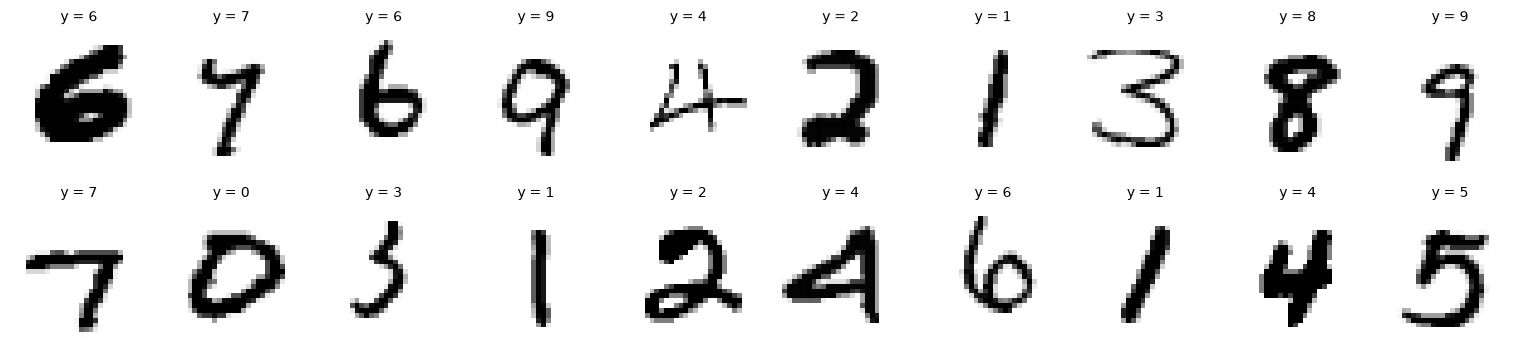

In [46]:
# 5.1. CÁC HÀM VẼ HÌNH DÙNG CHUNG
def show_images(X, titles, n_cols=10, size=1.4):
    n = len(X)
    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * 1.25 * n_rows))
    for ax in np.array(axes).reshape(-1):
        ax.axis("off")
    for k in range(n):
        ax = np.array(axes).reshape(-1)[k]
        # Khôi phục cường độ ảnh về dải hiển thị xám
        img = (X[k] * STD + MEAN).reshape(28, 28) if isinstance(X, torch.Tensor) else X[k].reshape(28, 28)
        ax.imshow(img, cmap="gray_r")
        ax.set_title(titles[k], fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_heatmap(M, row_labels, col_labels, row_name, col_name, title, cell_note=None):
    fig, ax = plt.subplots(figsize=(1.4 * len(col_labels) + 2, 0.8 * len(row_labels) + 1.5))
    ax.imshow(np.nan_to_num(M, nan=np.nanmin(M) if np.isfinite(M).any() else 0), cmap="viridis")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            txt = "phan ky" if np.isnan(M[i, j]) else f"{M[i, j]:.2f}"
            if cell_note is not None:
                txt += "\n" + cell_note(i, j)
            ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                    color="white" if np.isnan(M[i, j]) or M[i, j] < np.nanmedian(M) else "black")
    ax.set_xticks(range(len(col_labels))); ax.set_xticklabels(col_labels)
    ax.set_yticks(range(len(row_labels))); ax.set_yticklabels(row_labels)
    ax.set_xlabel(col_name); ax.set_ylabel(row_name); ax.set_title(title)
    plt.tight_layout()
    plt.show()


# Hiển thị thử nghiệm 20 mẫu đầu tiên của tập train
show_images(X_train[:20], [f"y = {int(t)}" for t in y_train[:20]])


---
## 6. KHÁM PHÁ VÀ PHÂN TÍCH DỮ LIỆU (EDA - EXPLORATORY DATA ANALYSIS)

- Mục (a) dùng cả ba tập: Train, Validation và Test để khảo sát phân bố lớp.
- Các mục (b), (c), (d) dùng ảnh gốc chưa chuẩn hóa của tập train:
`X_eda = Xtr_raw[tr_idx].float() / 255.0` (giá trị trong $[0, 1]$).

In [47]:
# 6.1. DỮ LIỆU EDA GỐC DÙNG CHO CÁC MỤC (B) ĐẾN (D)
X_eda = Xtr_raw[tr_idx].float() / 255.0     # (50000, 28, 28), ảnh gốc của tập train
y_eda = y_train
print("X_eda:", tuple(X_eda.shape), "| min:", X_eda.min().item(), "| max:", X_eda.max().item())


X_eda: (50000, 28, 28) | min: 0.0 | max: 1.0


### 6.2. Mục (a) — Phân bố lớp (Class Distribution)
**Yêu cầu:** Đếm số mẫu mỗi lớp ở train, val, test; vẽ biểu đồ cột tỉ lệ; in lớp ít nhất và nhiều nhất của từng tập.

 Tập Train: Lớp ít nhất là lớp 5 (4546 mẫu), Lớp nhiều nhất là lớp 1 (5613 mẫu)
 Tập Val  : Lớp ít nhất là lớp 5 (875 mẫu), Lớp nhiều nhất là lớp 1 (1129 mẫu)
 Tập Test : Lớp ít nhất là lớp 5 (892 mẫu), Lớp nhiều nhất là lớp 1 (1135 mẫu)


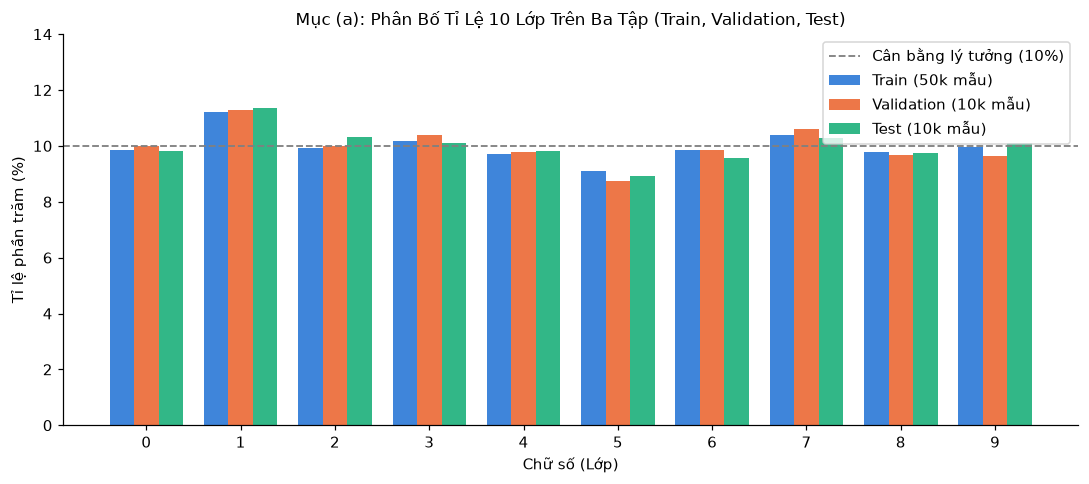

In [48]:
# 6.2. THỰC HIỆN MỤC (A): PHÂN BỐ LỚP TRÊN CẢ 3 TẬP
counts_tr = torch.bincount(y_train)
counts_va = torch.bincount(y_val)
counts_te = torch.bincount(y_test)

prop_tr = (counts_tr.float() / len(y_train) * 100).numpy()
prop_va = (counts_va.float() / len(y_val) * 100).numpy()
prop_te = (counts_te.float() / len(y_test) * 100).numpy()

# In thống kê lớp ít nhất và nhiều nhất của từng tập
classes = np.arange(10)
print(f" Tập Train: Lớp ít nhất là lớp {counts_tr.argmin().item()} ({counts_tr.min().item()} mẫu), Lớp nhiều nhất là lớp {counts_tr.argmax().item()} ({counts_tr.max().item()} mẫu)")
print(f" Tập Val  : Lớp ít nhất là lớp {counts_va.argmin().item()} ({counts_va.min().item()} mẫu), Lớp nhiều nhất là lớp {counts_va.argmax().item()} ({counts_va.max().item()} mẫu)")
print(f" Tập Test : Lớp ít nhất là lớp {counts_te.argmin().item()} ({counts_te.min().item()} mẫu), Lớp nhiều nhất là lớp {counts_te.argmax().item()} ({counts_te.max().item()} mẫu)")

# Vẽ biểu đồ cột tỉ lệ đối chiếu giữa 3 tập
fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.26
x = np.arange(10)

ax.bar(x - width, prop_tr, width, label=f"Train (50k mẫu)", color="#2a78d6", alpha=0.9)
ax.bar(x, prop_va, width, label=f"Validation (10k mẫu)", color="#eb6834", alpha=0.9)
ax.bar(x + width, prop_te, width, label=f"Test (10k mẫu)", color="#1baf7a", alpha=0.9)

ax.axhline(10.0, color="gray", linestyle="--", linewidth=1.2, label="Cân bằng lý tưởng (10%)")
ax.set_xlabel("Chữ số (Lớp)")
ax.set_ylabel("Tỉ lệ phần trăm (%)")
ax.set_title("Mục (a): Phân Bố Tỉ Lệ 10 Lớp Trên Ba Tập (Train, Validation, Test)")
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0, 14)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "eda_01_class_distribution.png"), dpi=150)
plt.show()


### 6.3. Mục (b) — Cường độ điểm ảnh và Điểm ảnh hằng số
**Yêu cầu:** In tỉ lệ pixel bằng 0 và bằng 1; vẽ histogram cường độ của các pixel khác 0; vẽ bản đồ độ lệch chuẩn của từng pixel và đếm số pixel luôn bằng 0 trên toàn tập train.

 Tổng số điểm ảnh trên tập train (50k x 784): 39,200,000
 Tỉ lệ pixel bằng 0 (nền đen tuyệt đối)   : 80.87% (31,701,892 pixels)
 Tỉ lệ pixel bằng 1 (nét trắng tối đa)     : 0.66% (259,890 pixels)
 Số pixel luôn bằng 0 trên toàn tập train : 71 / 784 pixels


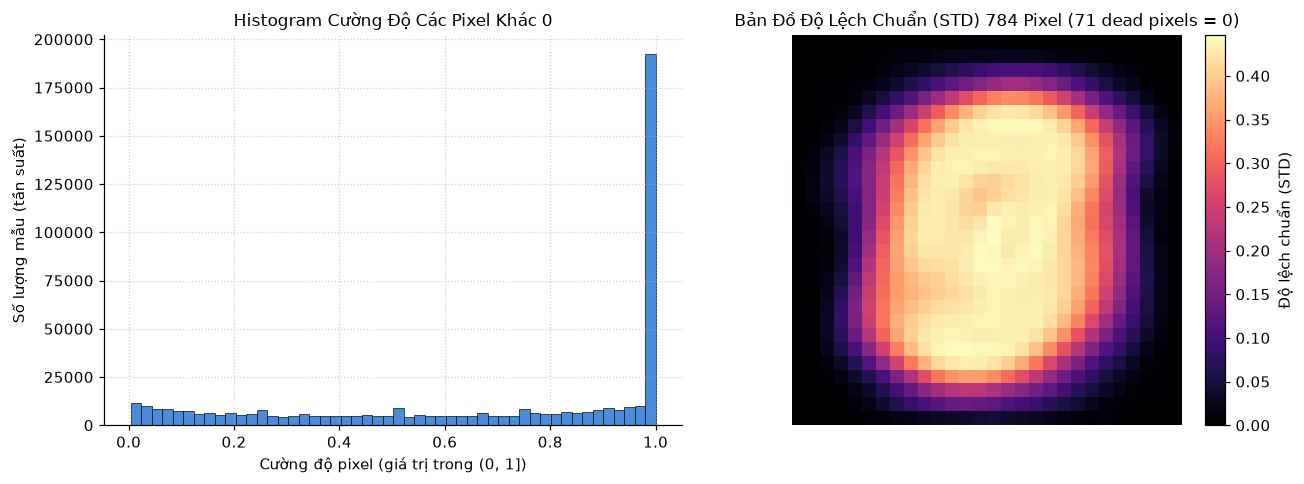

In [49]:
# 6.3. THỰC HIỆN MỤC (B): CƯỜNG ĐỘ PIXEL & DEAD PIXELS
total_pixels = X_eda.numel()
zero_count = (X_eda == 0.0).sum().item()
one_count  = (X_eda == 1.0).sum().item()

zero_ratio = zero_count / total_pixels * 100
one_ratio  = one_count / total_pixels * 100

print(f" Tổng số điểm ảnh trên tập train (50k x 784): {total_pixels:,}")
print(f" Tỉ lệ pixel bằng 0 (nền đen tuyệt đối)   : {zero_ratio:.2f}% ({zero_count:,} pixels)")
print(f" Tỉ lệ pixel bằng 1 (nét trắng tối đa)     : {one_ratio:.2f}% ({one_count:,} pixels)")

# Đếm số pixel luôn bằng 0 trên toàn tập train (Dead pixels)
is_always_zero = (X_eda == 0.0).all(dim=0)
dead_pixel_count = is_always_zero.sum().item()
print(f" Số pixel luôn bằng 0 trên toàn tập train : {dead_pixel_count} / 784 pixels")

# Độ lệch chuẩn của từng pixel trên toàn tập train
pixel_std_map = X_eda.std(dim=0).numpy()

# Lấy mẫu các pixel khác 0 để vẽ histogram
non_zero_pixels = X_eda[X_eda > 0.0].numpy()
if len(non_zero_pixels) > 500000:
    non_zero_sample = np.random.choice(non_zero_pixels, 500000, replace=False)
else:
    non_zero_sample = non_zero_pixels

# Trực quan hóa Histogram và Bản đồ độ lệch chuẩn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Histogram cường độ pixel khác 0
ax1.hist(non_zero_sample, bins=50, color="#2a78d6", edgecolor="black", linewidth=0.5, alpha=0.85)
ax1.set_title("Histogram Cường Độ Các Pixel Khác 0")
ax1.set_xlabel("Cường độ pixel (giá trị trong (0, 1])")
ax1.set_ylabel("Số lượng mẫu (tần suất)")
ax1.grid(True, linestyle=":", alpha=0.6)

# 2. Bản đồ độ lệch chuẩn của từng pixel
im = ax2.imshow(pixel_std_map, cmap="magma")
ax2.set_title(f"Bản Đồ Độ Lệch Chuẩn (STD) 784 Pixel ({dead_pixel_count} dead pixels = 0)")
ax2.axis("off")
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04, label="Độ lệch chuẩn (STD)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "eda_02_pixel_intensity_std_map.png"), dpi=150)
plt.show()


### 6.4. Mục (c) — Ảnh trung bình và Lượng mực tiêu thụ
**Yêu cầu:** Vẽ ảnh trung bình của từng chữ số; tính "lượng mực" (tổng cường độ của một ảnh) trung bình theo lớp và vẽ biểu đồ cột.

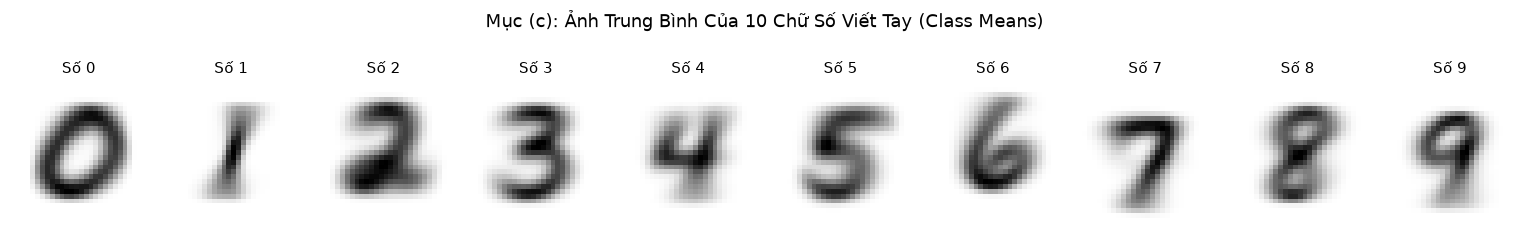

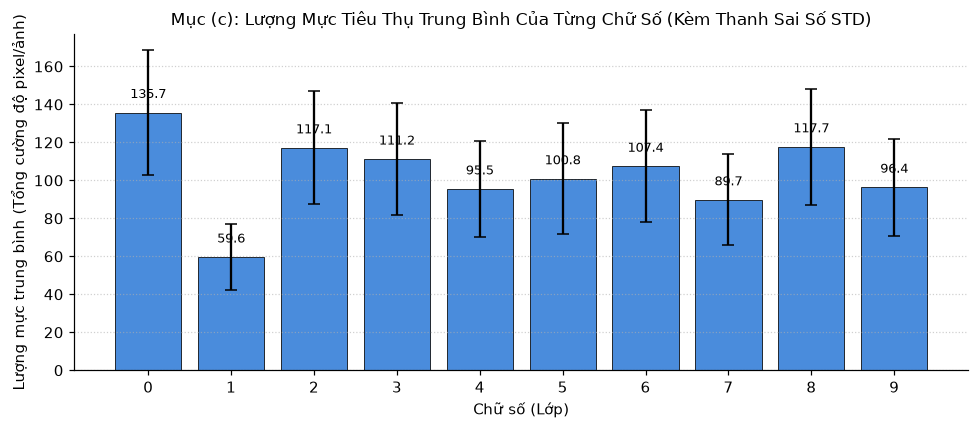

Nhận xét về lượng mực tiêu thụ:
 Chữ số tốn nhiều mực nhất: Số 0 (135.74) - do có đường nét bao kín rộng lớn.
 Chữ số tốn ít mực nhất   : Số 1 (59.57) - chỉ gồm một nét sổ dọc thanh mảnh.


In [50]:
# 6.4. THỰC HIỆN MỤC (C): ẢNH TRUNG BÌNH & LƯỢNG MỰC
class_means = torch.stack([X_eda[y_eda == c].mean(dim=0) for c in range(10)])

# Tính lượng mực của mỗi ảnh: tổng cường độ điểm ảnh của ảnh đó
ink_per_image = X_eda.sum(dim=(1, 2))  # (50000,)

# Tính lượng mực trung bình theo từng chữ số
class_inks = torch.tensor([ink_per_image[y_eda == c].mean().item() for c in range(10)])
ink_std    = torch.tensor([ink_per_image[y_eda == c].std().item() for c in range(10)])

# 1. Trực quan hóa 10 ảnh trung bình
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for c in range(10):
    axes[c].imshow(class_means[c], cmap="gray_r")
    axes[c].set_title(f"Số {c}", fontsize=10)
    axes[c].axis("off")
fig.suptitle("Mục (c): Ảnh Trung Bình Của 10 Chữ Số Viết Tay (Class Means)", fontsize=12, y=1.05)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "eda_03_mean_digits.png"), dpi=150, bbox_inches="tight")
plt.show()

# 2. Biểu đồ cột lượng mực tiêu thụ trung bình theo từng lớp
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(range(10), class_inks.numpy(), yerr=ink_std.numpy(), capsize=4, color="#2a78d6", alpha=0.85, edgecolor="black", linewidth=0.6)
ax.set_xticks(range(10))
ax.set_xlabel("Chữ số (Lớp)")
ax.set_ylabel("Lượng mực trung bình (Tổng cường độ pixel/ảnh)")
ax.set_title("Mục (c): Lượng Mực Tiêu Thụ Trung Bình Của Từng Chữ Số (Kèm Thanh Sai Số STD)")
ax.grid(True, linestyle=":", axis="y", alpha=0.6)

# Ghi chú giá trị trên đầu cột
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 6, f"{yval:.1f}", ha="center", va="bottom", fontsize=8.5)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "eda_04_class_ink_amount.png"), dpi=150)
plt.show()

print("Nhận xét về lượng mực tiêu thụ:")
print(f" Chữ số tốn nhiều mực nhất: Số {class_inks.argmax().item()} ({class_inks.max().item():.2f}) - do có đường nét bao kín rộng lớn.")
print(f" Chữ số tốn ít mực nhất   : Số {class_inks.argmin().item()} ({class_inks.min().item():.2f}) - chỉ gồm một nét sổ dọc thanh mảnh.")


### 6.5. Mục (d) — Độ tương đồng giữa các lớp
**Yêu cầu:** Tính khoảng cách Euclid giữa 10 ảnh trung bình (ma trận $10 \times 10$, vẽ heatmap), in 3 cặp gần nhau nhất.

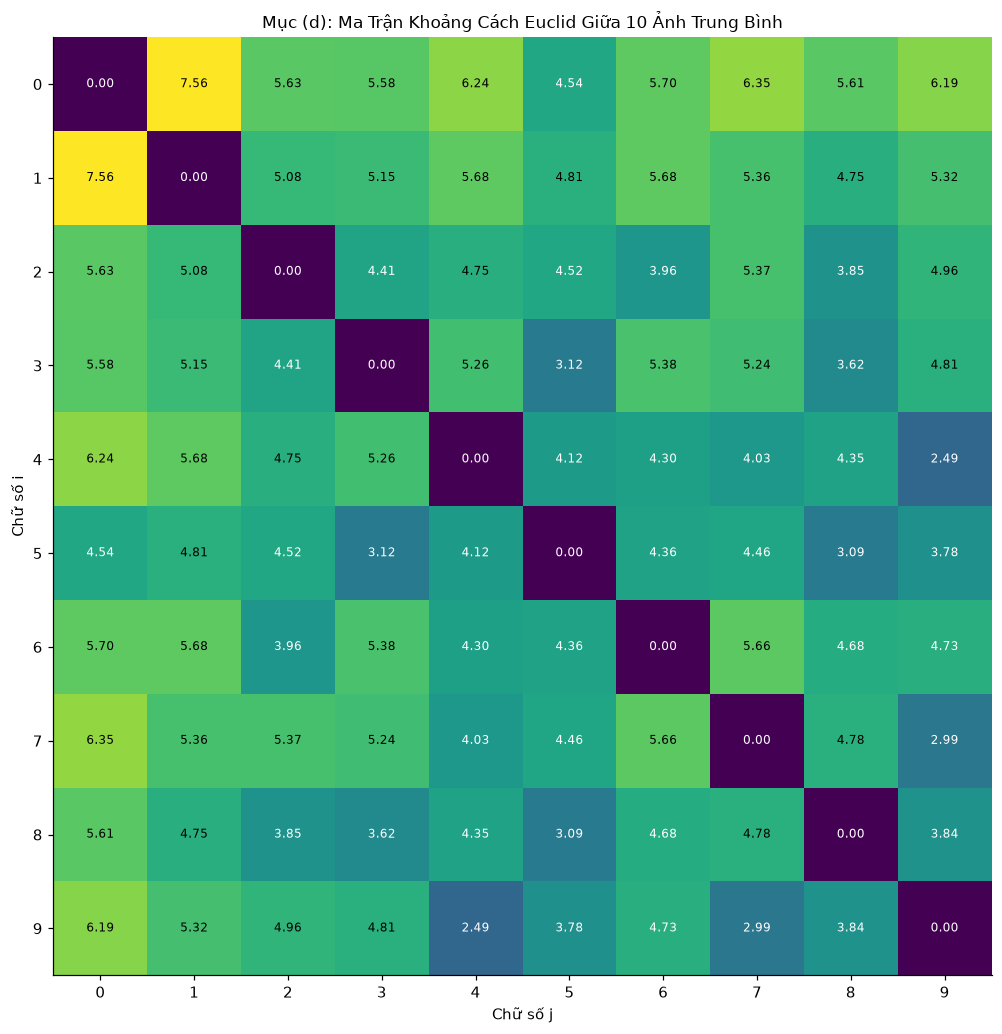

3 CẶP CHỮ SỐ GẦN NHAU NHẤT (DỄ BỊ PHÂN LỚP NHẦM LẪN NHẤT):
  1. Cặp (4, 9) với khoảng cách Euclid = 2.492
  2. Cặp (7, 9) với khoảng cách Euclid = 2.988
  3. Cặp (5, 8) với khoảng cách Euclid = 3.095


In [51]:
# 6.5. THỰC HIỆN MỤC (D): KHOẢNG CÁCH EUCLID & HEATMAP
class_means_flat = class_means.reshape(10, -1)  # (10, 784)

# Tính ma trận khoảng cách Euclid 10 x 10 bằng hàm chuẩn torch.cdist
D = torch.cdist(class_means_flat, class_means_flat).numpy()

# Vẽ Heatmap sử dụng hàm plot_heatmap
class_labels = [str(i) for i in range(10)]
plot_heatmap(
    D,
    row_labels=class_labels,
    col_labels=class_labels,
    row_name="Chữ số i",
    col_name="Chữ số j",
    title="Mục (d): Ma Trận Khoảng Cách Euclid Giữa 10 Ảnh Trung Bình"
)

# Tìm 3 cặp chữ số gần nhau nhất (khoảng cách nhỏ nhất, loại bỏ đường chéo i == j)
pairs = []
for i in range(10):
    for j in range(i + 1, 10):
        pairs.append((D[i, j], i, j))

pairs.sort(key=lambda item: item[0])

print("3 CẶP CHỮ SỐ GẦN NHAU NHẤT (DỄ BỊ PHÂN LỚP NHẦM LẪN NHẤT):")
for rank, (dist, c1, c2) in enumerate(pairs[:3], start=1):
    print(f"  {rank}. Cặp ({c1}, {c2}) với khoảng cách Euclid = {dist:.3f}")


---
## 7. XUẤT VÀ LƯU TRỮ DỮ LIỆU ĐÃ TIỀN XỬ LÝ

1. Lưu toàn bộ các tập dữ liệu phẳng (`X_train`, `X_val`, `X_test`), dạng ảnh 2D (`X_train_img`, `X_val_img`, `X_test_img`), và nhãn (`y_train`, `y_val`, `y_test`) vào tệp nén `data/processed/mnist_preprocessed.npz`.
2. Xây dựng hàm tiện ích `load_preprocessed_mnist()` giúp các Phase sau nạp dữ liệu tức thì chỉ trong vài giây.


In [52]:
# 7.1. LƯU DỮ LIỆU VÀO DATA/PROCESSED/MNIST_PREPROCESSED.NPZ
processed_filepath = os.path.join(PROCESSED_DIR, "mnist_preprocessed.npz")

# Lưu trữ nén định dạng numpy
np.savez_compressed(
    processed_filepath,
    # 1. Dạng chuẩn hóa z-score toàn cục phẳng (N, 784) (cho MLP / GD)
    X_train_flat=X_train.numpy(),
    X_val_flat=X_val.numpy(),
    X_test_flat=X_test.numpy(),
    
    # 2. Dạng chuẩn hóa Min-Max [0, 1] phẳng (N, 784) (cho Naive Bayes / Ensemble)
    X_train_minmax=X_train_minmax,
    X_val_minmax=X_val_minmax,
    X_test_minmax=X_test_minmax,
    
    # 3. Dạng chuẩn hóa Standardizer từng đặc trưng (N, 784)
    X_train_feat_std=X_train_feat_std,
    X_val_feat_std=X_val_feat_std,
    X_test_feat_std=X_test_feat_std,
    
    # 4. Dạng ảnh gốc 2D (N, 28, 28) dải [0, 1] (cho CNN và trực quan hóa)
    X_train_img=X_train_img,
    X_val_img=X_val_img,
    X_test_img=X_test_img,
    
    # 5. Mảng nhãn
    y_train=y_train.numpy(),
    y_val=y_val.numpy(),
    y_test=y_test.numpy(),
    
    # 6. Các thông số thống kê
    mean=MEAN,
    std=STD,
    seed=SEED
)

filesize_mb = os.path.getsize(processed_filepath) / (1024 * 1024)
print(f"[✓] Đã lưu thành công dữ liệu tiền xử lý tại: {processed_filepath} ({filesize_mb:.2f} MB)")


def load_preprocessed_mnist(filepath=processed_filepath):
    """
    Hàm tiện ích nạp dữ liệu tiền xử lý nhanh chóng cho Phase 1, Phase 2, Phase 3.
    Trả về từ điển chứa đầy đủ các tập dữ liệu cần thiết.
    """
    data = np.load(filepath)
    return {
        "X_train_flat": data["X_train_flat"],
        "X_val_flat": data["X_val_flat"],
        "X_test_flat": data["X_test_flat"],
        "X_train_minmax": data["X_train_minmax"],
        "X_val_minmax": data["X_val_minmax"],
        "X_test_minmax": data["X_test_minmax"],
        "X_train_feat_std": data["X_train_feat_std"],
        "X_val_feat_std": data["X_val_feat_std"],
        "X_test_feat_std": data["X_test_feat_std"],
        "X_train_img": data["X_train_img"],
        "X_val_img": data["X_val_img"],
        "X_test_img": data["X_test_img"],
        "y_train": data["y_train"],
        "y_val": data["y_val"],
        "y_test": data["y_test"],
        "mean": float(data["mean"]),
        "std": float(data["std"]),
        "seed": int(data["seed"])
    }


# Kiểm tra thử nghiệm hàm load
test_load = load_preprocessed_mnist()
print(f" Nạp thử thành công! X_train_flat: {test_load['X_train_flat'].shape}, y_train: {test_load['y_train'].shape}")


[✓] Đã lưu thành công dữ liệu tiền xử lý tại: ./data/processed/mnist_preprocessed.npz (93.68 MB)
 Nạp thử thành công! X_train_flat: (50000, 784), y_train: (50000,)
